<a href="https://colab.research.google.com/github/wildemar66/Project_Analisis_churn/blob/main/notebooks/Analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# jalur folder
BASE_PATH = '/content/drive/MyDrive/Project_Analisis_churn'
REPORTS = f'{BASE_PATH}/Reports'

# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

Mounted at /content/drive


# Load Data

In [2]:
df = pd.read_csv(f'{BASE_PATH}/Data/Processed/data_bersih.csv')
df.sample(5)

,Unnamed: 0,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
5265,5265,1240-HCBOH,1,United States,California,Windsor,95492,"38.527297, -122.810044",38.527297,-122.810044,Female,No,No,No,67,Yes,Yes,No,No,No,No,No,No,No,Two year,Yes,Mailed check,26.10,1759.55,No,0,42,6466,NaN
3429,3429,8819-IMISP,1,United States,California,Redlands,92373,"34.003243, -117.138286",34.003243,-117.138286,Male,No,No,No,31,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,80.45,2429.10,No,0,49,4684,NaN
119,119,0306-JAELE,1,United States,California,Tecopa,92389,"35.824572, -116.274755",35.824572,-116.274755,Male,No,No,No,5,Yes,No,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,96.10,453.40,Yes,1,66,4192,Competitor had better devices
5974,5974,5982-FPVQN,1,United States,California,Camarillo,93012,"34.205504, -118.993111",34.205504,-118.993111,Female,No,Yes,Yes,37,Yes,Yes,Fiber optic,No,Yes,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,95.15,3532.85,No,0,22,3407,NaN
1463,1463,5087-SUURX,1,United States,California,Yorba Linda,92887,"33.884073, -117.732197",33.884073,-117.732197,Female,No,Yes,No,18,No,No,DSL,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,39.05,669.85,Yes,1,66,2601,Lack of self-service on Website


In [3]:
# Hapus kolom yang tidak diperlukan
hps_kolom = df[['Unnamed: 0','Zip Code','Lat Long','Latitude','Longitude']]
df = df.drop(columns=hps_kolom)

In [4]:
df.sample(5)

,CustomerID,Count,Country,State,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
292,4081-DYXAV,1,United States,California,San Jose,Female,No,No,No,19,No,No,DSL,No,No,No,No,Yes,Yes,One year,Yes,Credit card (automatic),44.85,893.55,Yes,1,72,5182,Competitor offered higher download speeds
2104,5027-YOCXN,1,United States,California,Cardiff By The Sea,Male,No,Yes,No,51,Yes,Yes,Fiber optic,Yes,Yes,No,Yes,Yes,Yes,One year,No,Credit card (automatic),110.05,5686.40,No,0,56,5604,NaN
3986,4146-SVFUD,1,United States,California,Modesto,Male,No,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,44.60,44.60,No,0,77,4864,NaN
4245,3594-IVHJZ,1,United States,California,French Gulch,Female,No,No,No,2,Yes,No,No,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,20.45,42.45,No,0,56,2606,NaN
6181,8241-JUIQO,1,United States,California,Sunnyvale,Female,No,No,No,61,Yes,No,No,No,No,No,No,No,No,One year,No,Bank transfer (automatic),19.45,1336.35,No,0,26,4559,NaN


### 1. Berapa banyak customer yang churn ?

In [5]:
total_churn = df['Churn Label'].value_counts()
total_churn

,count
Churn Label,
No,5174
Yes,1869


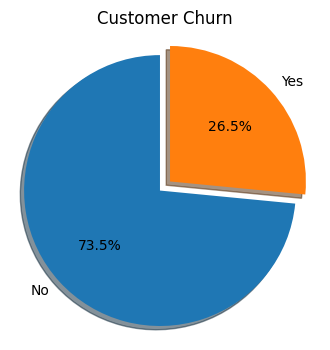

In [6]:
# Membuat pie chart
plt.figure(figsize=(4, 4))
plt.pie(total_churn, labels=total_churn.index, autopct='%1.1f%%',
        explode=(0, 0.1), shadow=True,startangle=90)
plt.axis('equal')
plt.title('Customer Churn')
plt.show()


* Total Customer yang churn cukup besar, yaitu 26,5%. Butuh analisis lebih dalam untuk mengetahui penyebab churn 26,5% tersebut.

### 2. Apakah kontrak yang lebih pendek mempengaruhi customer churn ?

In [7]:
kontrak_churn = pd.crosstab(df['Contract'],df['Churn Label'],normalize='index')
kontrak_churn

Churn Label,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


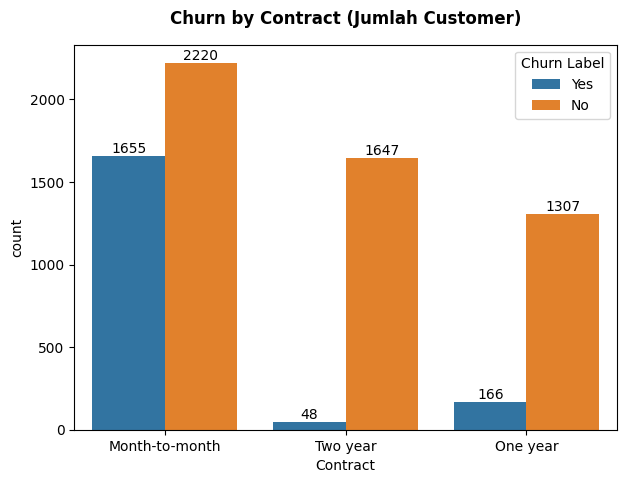

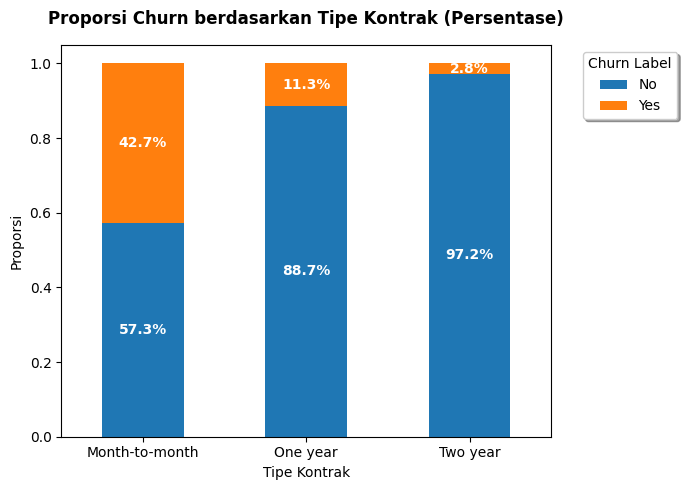

In [8]:
# 1. Menampilkan angka pada sns.countplot
plt.figure(figsize=(7,5))
ax1 = sns.countplot(data=df, x='Contract', hue='Churn Label')
plt.title('Churn by Contract (Jumlah Customer)', fontsize=12, fontweight='bold', pad=15)

# Menambahkan label angka di setiap batang
for container in ax1.containers:
    ax1.bar_label(container)

plt.show()

# 2. Menampilkan angka persentase pada Stacked Bar Chart dengan Legend yang Rapi
ax2 = kontrak_churn.plot(kind='bar', figsize=(7, 5), stacked=True, color=['#1f77b4', '#ff7f0e'])
plt.title('Proporsi Churn berdasarkan Tipe Kontrak (Persentase)', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Proporsi')
plt.xlabel('Tipe Kontrak')
plt.xticks(rotation=0)

# Merapikan Legend (dipindahkan ke sebelah kanan luar diagram agar tidak menumpuk)
plt.legend(title='Churn Label', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True, shadow=True)

# Menambahkan label persentase di dalam batang
for container in ax2.containers:
    # Menampilkan label dengan format persentase (1 desimal, misal: 42.7%)
    ax2.bar_label(container, fmt=lambda x: f'{x*100:.1f}%' if x > 0 else '', label_type='center', fontweight='bold', color='white')

plt.tight_layout()
plt.show()

* Dari total customer yang ada, kebanyakan memiliki kontrak `month-to-month`. Dan penyumbang churn terbanyak juga dari jenis kontrak `month-to-month` sebesar 42,7% dari total customer dengan kontrak tersebut. perlu perhatian serius untuk customer dengan kontrak `month-to-month`.
* Customer dengan kontrak `one year` sudah lebih nyaman dan loyal, meskipun ada 11,3% customer yang churn dikelompok tersebut.
* Customer dengan kontrak `two year` sudah sangat nyaman berlangganan dan sudah loyal.

### 3. Analisis Alasan Churn (Churn Reason Analysis)
Mari kita analisis alasan utama mengapa customer memutuskan untuk berhenti berlangganan (churn) menggunakan kolom `Churn Reason`.

/tmp/ipykernel_3992/3530684789.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_reasons.head(10), x='Count', y='Churn Reason', palette='Reds_r')


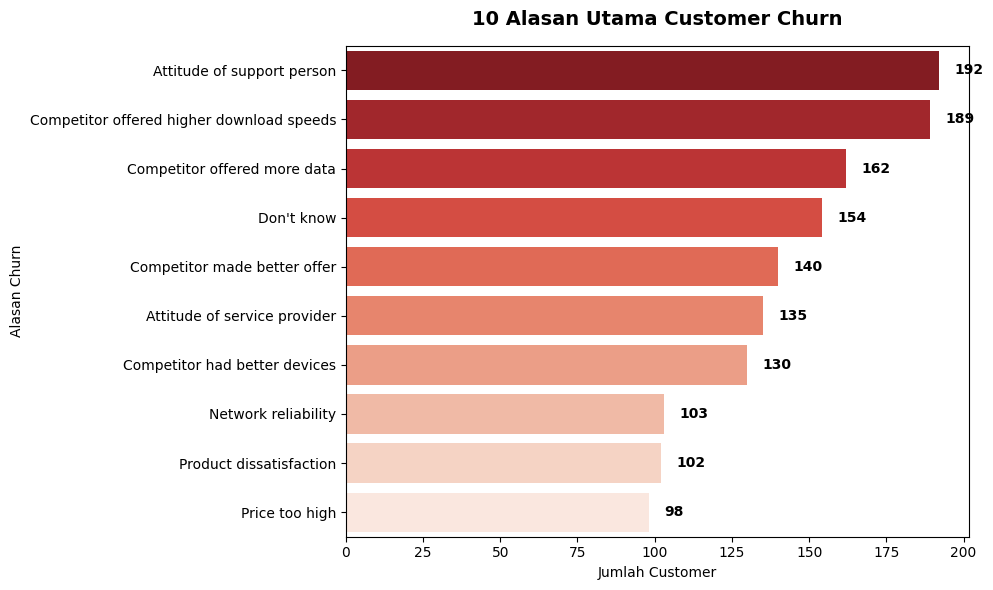

In [9]:
# Memfilter data customer yang hanya melakukan churn
df_churn = df[df['Churn Label'] == 'Yes']

# Menghitung frekuensi alasan churn
churn_reasons = df_churn['Churn Reason'].value_counts().reset_index()
churn_reasons.columns = ['Churn Reason', 'Count']

# Visualisasi Alasan Churn Teratas
plt.figure(figsize=(10, 6))
sns.barplot(data=churn_reasons.head(10), x='Count', y='Churn Reason', palette='Reds_r')
plt.title('10 Alasan Utama Customer Churn', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jumlah Customer')
plt.ylabel('Alasan Churn')

# Menampilkan angka di ujung diagram batang
for index, value in enumerate(churn_reasons.head(10)['Count']):
    plt.text(value + 5, index, str(value), va='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Analisis Distribusi Tenure (Kapan Customer Paling Rentan Churn?)

Melihat sebaran masa berlangganan (`Tenure Months`) bagi customer yang bertahan vs customer yang churn.

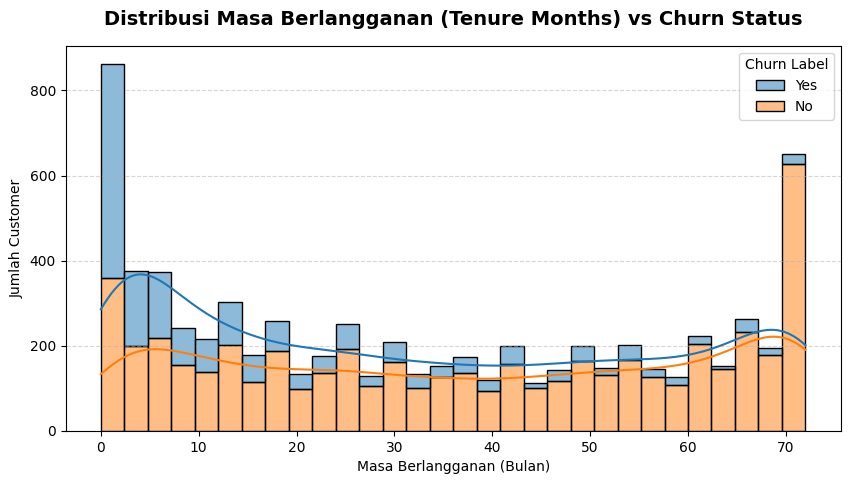

In [10]:
# Visualisasi distribusi Tenure Months
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Tenure Months', hue='Churn Label', kde=True, bins=30, multiple='stack', palette=['#1f77b4', '#ff7f0e'])
plt.title('Distribusi Masa Berlangganan (Tenure Months) vs Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Masa Berlangganan (Bulan)')
plt.ylabel('Jumlah Customer')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### 5. Analisis Layanan Tambahan (Internet Service vs Churn)
Melihat apakah jenis teknologi internet tertentu menyumbang persentase churn yang besar.

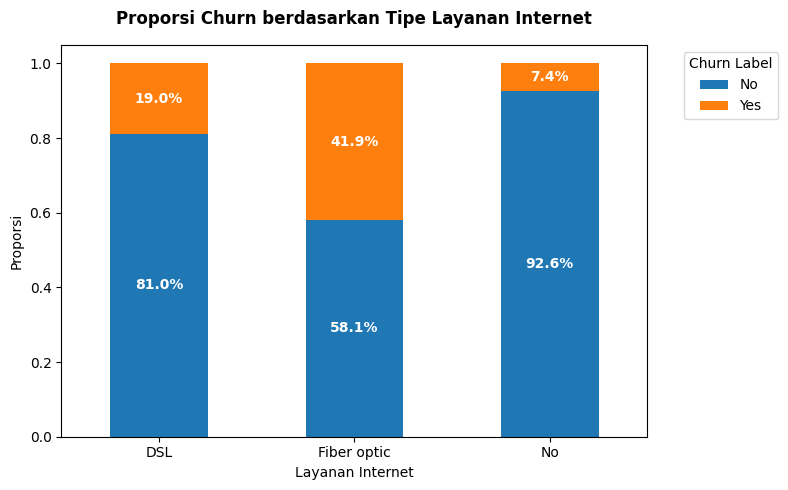

In [11]:
# Crosstab antara Internet Service dan Churn
internet_churn = pd.crosstab(df['Internet Service'], df['Churn Label'], normalize='index')

# Visualisasi Stacked Bar
ax = internet_churn.plot(kind='bar', figsize=(8, 5), stacked=True, color=['#1f77b4', '#ff7f0e'])
plt.title('Proporsi Churn berdasarkan Tipe Layanan Internet', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Proporsi')
plt.xlabel('Layanan Internet')
plt.xticks(rotation=0)
plt.legend(title='Churn Label', bbox_to_anchor=(1.05, 1), loc='upper left')

# Menambahkan angka persentase
for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f'{x*100:.1f}%' if x > 0 else '', label_type='center', fontweight='bold', color='white')

plt.tight_layout()
plt.show()